# Week 6 — Feature Engineering and Comparison

Add property ratios, property age, and school-district location features. Retrain
Linear Regression, Decision Tree, and Random Forest on three feature sets:

1. Original predictors from Notebook 02.
2. Original predictors plus four numeric features and two ratio-missing flags.
3. Numeric features plus the school-district features.

Use the same properties and chronological split for every comparison.

## 1. Import libraries

In [20]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

## 2. Reuse Notebook 02

`%run` executes the existing preprocessing notebook and brings its variables into
this notebook. It also resaves the original four prepared CSVs as Notebook 02
normally does.

This preserves the original cleaning rules, training-only imputation, and encoded
predictors. `train_df` and `test_df` retain dates and coordinates for engineering.
With the current data, training is May 2025–March 2026 and testing is April 2026.

In [21]:
%run ./02_preprocessing.ipynb

,MissingCount,MissingPercent
CloseDate,0,0.00
ClosePrice,0,0.00
LivingArea,73,0.06
BedroomsTotal,0,0.00
BathroomsTotalInteger,13,0.01
LotSizeSquareFeet,2306,1.76
YearBuilt,91,0.07
Latitude,0,0.00
Longitude,0,0.00
City,39,0.03


Training months: 2025-05 through 2026-03
Test month: 2026-04
Training rows: 117341 Test rows: 12279


LivingArea               1815.000000
BedroomsTotal               3.000000
BathroomsTotalInteger       2.000000
LotSizeSquareFeet        7274.000000
YearBuilt                1976.000000
Latitude                   34.081950
Longitude                -118.023632
Name: TrainingFillValue, dtype: float64

## 3. Create the numeric features

| Feature | Meaning |
|---|---|
| BedBathRatio | Bedrooms divided by bathrooms; 4 beds / 2 baths = 2. |
| PropertyAge | Sale year minus YearBuilt; built in 2000 and sold in 2026 = 26. |
| LivingAreaPerBedroom | Total living area divided by bedrooms; this is not actual bedroom size. |
| LotToLivingAreaRatio | Lot size divided by living area; this is not building footprint coverage. |

Notebook 02 already imputed missing input measurements and retained their flags.
Derived values are therefore estimates when their input values were imputed.
Age uses calendar years, so it is approximate. Sale year is the historical valuation
date proxy; for a live prediction, use the requested valuation year instead of an
unknown future closing date. CloseDate and ClosePrice are not added to X.

Zero bathrooms or bedrooms produce undefined ratios. Preserve that information
with missing flags before filling the ratios.

In [22]:
X_train_numeric = X_train.copy()
X_test_numeric = X_test.copy()

ratio_columns = ["BedBathRatio", "LivingAreaPerBedroom", "LotToLivingAreaRatio"]

for properties, features in [
    (train_df, X_train_numeric),
    (test_df, X_test_numeric)
]:
    bathrooms = properties["BathroomsTotalInteger"].where(
        properties["BathroomsTotalInteger"] > 0
    )
    bedrooms = properties["BedroomsTotal"].where(properties["BedroomsTotal"] > 0)
    living_area = properties["LivingArea"].where(properties["LivingArea"] > 0)

    features["BedBathRatio"] = properties["BedroomsTotal"] / bathrooms
    features["PropertyAge"] = properties["CloseDate"].dt.year - properties["YearBuilt"]
    features["LivingAreaPerBedroom"] = properties["LivingArea"] / bedrooms
    features["LotToLivingAreaRatio"] = properties["LotSizeSquareFeet"] / living_area

    for column in ["BedBathRatio", "LivingAreaPerBedroom"]:
        features[column + "_Missing"] = features[column].isna().astype(int)

## 4. Fill undefined ratios and inspect the numeric features

AVM best practices: learn replacement values from training data only, then apply
the same values to testing. Keep all the original predictors and row indexes.

In [23]:
ratio_fill_values = X_train_numeric[ratio_columns].median()
assert ratio_fill_values.notna().all(), "A ratio has no valid training values."

for features in [X_train_numeric, X_test_numeric]:
    features[ratio_columns] = features[ratio_columns].fillna(ratio_fill_values)

numeric_features = ratio_columns + ["PropertyAge"]
for features in [X_train_numeric, X_test_numeric]:
    assert np.isfinite(features[numeric_features].to_numpy()).all()
    assert features["PropertyAge"].ge(0).all()

display(ratio_fill_values.rename("TrainingFillValue"))
display(X_train_numeric[numeric_features].describe().T)

BedBathRatio              1.500000
LivingAreaPerBedroom    540.750000
LotToLivingAreaRatio      4.228849
Name: TrainingFillValue, dtype: float64

,count,mean,std,min,25%,50%,75%,max
BedBathRatio,117341.0,1.458413,0.469762,0.000000,1.000000,1.500000,1.500000,7.500000e+00
LivingAreaPerBedroom,117341.0,577.028029,188.634628,35.000000,447.500000,540.750000,662.800000,3.529000e+03
LotToLivingAreaRatio,117341.0,220.532241,10035.055176,0.000017,2.998909,4.228849,5.977255,1.570930e+06
PropertyAge,117341.0,49.443639,27.536990,0.000000,27.000000,49.000000,70.000000,2.490000e+02


## 5. Load the school-district boundaries

Read the uploaded 2024–25 boundary file directly from its ZIP. Shapefiles shorten
field names, so rename `DistrictTy` to `DistrictType` and `CDCode` to `DistrictCode`.
Use only district identity and geometry; this is a location feature, not a school
quality score. Geometry means the mapped shape of each district.

Repair invalid shapes, then convert boundaries to the same coordinate reference
system as property longitude/latitude. `EPSG:4326` means longitude/latitude in degrees.
The fixed 2024–25 boundary snapshot is an approximation for sales in 2025–26;
later boundary changes are not represented.

In [24]:
districts = gpd.read_file("../data/raw/DistrictAreas2425.zip")
districts = districts[["CDCode", "DistrictTy", "geometry"]].rename(columns={
    "CDCode": "DistrictCode",
    "DistrictTy": "DistrictType"
})

print("Invalid district shapes repaired:", (~districts.geometry.is_valid).sum())
districts["geometry"] = districts.geometry.make_valid()
districts = districts.to_crs("EPSG:4326")
assert districts.geometry.is_valid.all()

display(districts["DistrictType"].value_counts())

Invalid district shapes repaired: 7


DistrictType
Elementary    516
Unified       345
High           76
Name: count, dtype: int64

## 6. Define the school-district matching function

A spatial join finds which district polygons contain or touch each property's
coordinate point. Longitude is x; latitude is y. This function applies the same
steps to the training and test properties.

Elementary and high-school boundaries can overlap normally. Match each type
separately and keep unified districts in their own column. A unified-district
property may legitimately have no separate elementary/high-school district match.

`intersects` includes points on boundaries. If a point matches more than one
distinct district of the SAME type, label it `Ambiguous` rather than choosing one
arbitrarily or duplicating the property row. `NotMatched` means that type had no
match. A missing flag identifies properties with no unambiguous match of any type.

In [25]:
district_types = {
    "Elementary": "ElementaryDistrict",
    "High": "HighSchoolDistrict",
    "Unified": "UnifiedDistrict"
}
district_columns = list(district_types.values())

def find_school_districts(properties):
    points = gpd.GeoDataFrame(
        index=properties.index,
        geometry=gpd.points_from_xy(properties["Longitude"], properties["Latitude"]),
        crs="EPSG:4326"
    )
    assignments = pd.DataFrame(index=properties.index)

    for district_type, column in district_types.items():
        polygons = districts.loc[
            districts["DistrictType"].eq(district_type),
            ["DistrictCode", "geometry"]
        ]
        matches = gpd.sjoin(points, polygons, how="left", predicate="intersects")

        # Collapse matches back to one row per property without losing row order.
        counts = matches.groupby(level=0)["DistrictCode"].nunique()
        codes = matches.groupby(level=0)["DistrictCode"].first()
        codes = codes.mask(counts > 1, "Ambiguous").fillna("NotMatched")
        assignments[column] = codes.reindex(properties.index)

    assignments["SchoolDistrictMissing"] = (
        assignments[district_columns].isin(["NotMatched", "Ambiguous"])
        .all(axis=1).astype(int)
    )
    return assignments

## 7. Match the training and test properties

Report how many properties received at least one unambiguous district match.
Do not drop unmatched properties: every feature set must use the same rows.

In [26]:
train_districts = find_school_districts(train_df)
test_districts = find_school_districts(test_df)

district_match_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Rows": [len(train_districts), len(test_districts)],
    "AnyDistrictMatchPercent": [
        100 * (1 - train_districts["SchoolDistrictMissing"].mean()),
        100 * (1 - test_districts["SchoolDistrictMissing"].mean())
    ],
    "RowsWithAmbiguousType": [
        train_districts[district_columns].eq("Ambiguous").any(axis=1).sum(),
        test_districts[district_columns].eq("Ambiguous").any(axis=1).sum()
    ]
})

display(train_districts.head())
display(district_match_summary.round(2))

,ElementaryDistrict,HighSchoolDistrict,UnifiedDistrict,SchoolDistrictMissing
0,NotMatched,NotMatched,3768338,0
1,NotMatched,NotMatched,3667843,0
2,NotMatched,NotMatched,3073635,0
3,NotMatched,NotMatched,1964733,0
4,3066498,3066548,NotMatched,0


,Dataset,Rows,AnyDistrictMatchPercent,RowsWithAmbiguousType
0,Training,117341,99.99,0
1,Test,12279,99.99,0


## 8. Encode the district categories

District codes are labels, not numeric measurements. Use the same one-hot approach
as Notebook 02. Keep codes with at least 20 training examples, group rarer or unseen
test codes as `Other`, and retain `NotMatched` / `Ambiguous` as explicit labels.

Learn the category list from training only. Reindex the encoded test columns to
match training. If `Other` never occurred in training, an unseen test code receives
all zeros for that district type because there is no learned `Other` column.

In [27]:
train_district_categories = train_districts.copy()
test_district_categories = test_districts.copy()
minimum_district_count = 20

for column in district_columns:
    counts = train_districts[column].value_counts()
    keep_codes = counts[counts >= minimum_district_count].index

    for data in [train_district_categories, test_district_categories]:
        keep = data[column].isin(keep_codes) | data[column].isin(["NotMatched", "Ambiguous"])
        data[column] = data[column].where(keep, "Other")

train_district_encoded = pd.get_dummies(
    train_district_categories, columns=district_columns, dtype=bool
)
test_district_encoded = pd.get_dummies(
    test_district_categories, columns=district_columns, dtype=bool
).reindex(columns=train_district_encoded.columns, fill_value=False)

## 9. Combine features and check the datasets

Keep three feature sets so we can see the effect of the numeric features first,
then the additional effect of districts. Preserve the original X and y values.
No feature uses ClosePrice or a price aggregate. No scaling is added in this step.

In [28]:
X_train_all = pd.concat([X_train_numeric, train_district_encoded], axis=1)
X_test_all = pd.concat([X_test_numeric, test_district_encoded], axis=1)

feature_sets = {
    "Original": (X_train, X_test),
    "Numeric features": (X_train_numeric, X_test_numeric),
    "Numeric + districts": (X_train_all, X_test_all)
}

for name, (training, testing) in feature_sets.items():
    assert training.index.equals(y_train.index)
    assert testing.index.equals(y_test.index)
    assert training.columns.equals(testing.columns)
    assert training.columns.is_unique
    assert not training.isna().any().any()
    assert not testing.isna().any().any()
    assert "ClosePrice" not in training.columns
    assert "CloseDate" not in training.columns
    print(name, "— training rows:", len(training), "test rows:", len(testing),
          "predictor columns:", training.shape[1])

Original — training rows: 117341 test rows: 12279 predictor columns: 1340
Numeric features — training rows: 117341 test rows: 12279 predictor columns: 1346
Numeric + districts — training rows: 117341 test rows: 12279 predictor columns: 1769


## 10. Retrain the three models on each feature set

Recalculate the original results on these exact rows, then compare the new sets.
This avoids relying on an old results file from a different data run. Keep the
Week 5 settings unchanged: depth 18, minimum leaf size 5, seed 42, and 100 trees.
All other model settings remain at their defaults.

Each model learns only from training rows. The test set is used for prediction
and scoring. Record training R² too, as a diagnostic for possible overfitting.
This fits nine models, so the forests can take several minutes on the full data.

In [29]:
results = []

for feature_set, (training, testing) in feature_sets.items():
    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(
            max_depth=18, min_samples_leaf=5, random_state=42
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=100, max_depth=18, min_samples_leaf=5,
            random_state=42, n_jobs=-1
        )
    }

    for model_name, model in models.items():
        print("Training:", feature_set, "—", model_name, flush=True)
        model.fit(training, y_train)
        predictions = model.predict(testing)

        results.append({
            "FeatureSet": feature_set,
            "Model": model_name,
            "Train_R2": model.score(training, y_train),
            "Test_R2": r2_score(y_test, predictions),
            "TrainingRows": len(training),
            "TestRows": len(testing),
            "PredictorColumns": training.shape[1]
        })

Training: Original — Linear Regression
Training: Original — Decision Tree
Training: Original — Random Forest
Training: Numeric features — Linear Regression
Training: Numeric features — Decision Tree
Training: Numeric features — Random Forest
Training: Numeric + districts — Linear Regression
Training: Numeric + districts — Decision Tree
Training: Numeric + districts — Random Forest


## 11. Compare old versus new features

Higher test R² is better. ChangeFromOriginal compares each result with the same
model's original-feature result. A positive value indicates an improvement on
this test month. It is an absolute R² difference, not a percentage of correct prices.

In [30]:
comparison = pd.DataFrame(results)
original_scores = comparison.loc[
    comparison["FeatureSet"].eq("Original")
].set_index("Model")["Test_R2"]

comparison["ChangeFromOriginal"] = (
    comparison["Test_R2"] - comparison["Model"].map(original_scores)
)
comparison["TrainTestGap"] = comparison["Train_R2"] - comparison["Test_R2"]
display(comparison.round(4))

test_r2_table = comparison.pivot(index="Model", columns="FeatureSet", values="Test_R2")
test_r2_table = test_r2_table.reindex(
    index=["Linear Regression", "Decision Tree", "Random Forest"],
    columns=list(feature_sets)
)
display(test_r2_table.round(4))

,FeatureSet,Model,Train_R2,Test_R2,TrainingRows,TestRows,PredictorColumns,ChangeFromOriginal,TrainTestGap
0,Original,Linear Regression,0.8137,0.8159,117341,12279,1340,0.0000,-0.0023
1,Original,Decision Tree,0.9208,0.8025,117341,12279,1340,0.0000,0.1182
2,Original,Random Forest,0.9264,0.8674,117341,12279,1340,0.0000,0.0590
3,Numeric features,Linear Regression,0.8193,0.8225,117341,12279,1346,0.0066,-0.0032
4,Numeric features,Decision Tree,0.9202,0.8014,117341,12279,1346,-0.0011,0.1188
5,Numeric features,Random Forest,0.9275,0.8633,117341,12279,1346,-0.0041,0.0642
6,Numeric + districts,Linear Regression,0.8276,0.8254,117341,12279,1769,0.0095,0.0022
7,Numeric + districts,Decision Tree,0.9089,0.7978,117341,12279,1769,-0.0047,0.1111
8,Numeric + districts,Random Forest,0.9259,0.8625,117341,12279,1769,-0.0049,0.0634


FeatureSet,Original,Numeric features,Numeric + districts
Model,,,
Linear Regression,0.8159,0.8225,0.8254
Decision Tree,0.8025,0.8014,0.7978
Random Forest,0.8674,0.8633,0.8625


## 12. Graph the comparison

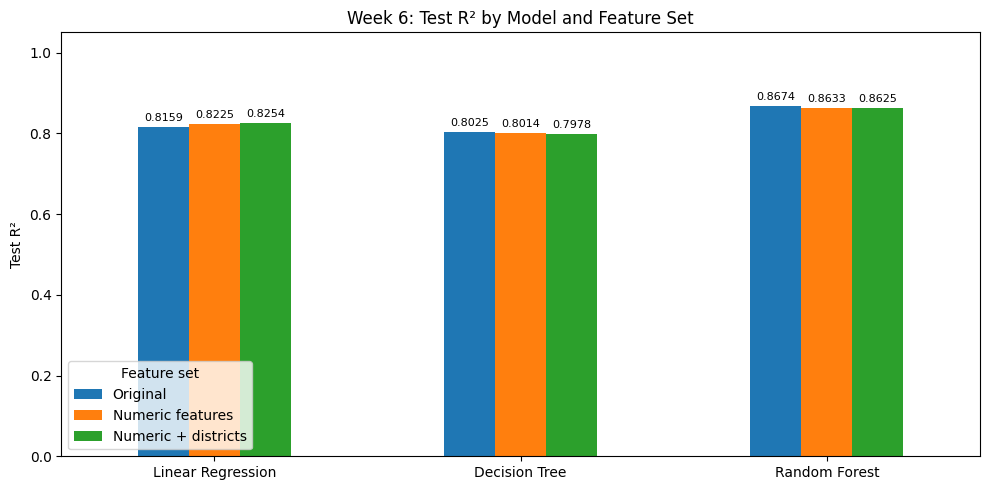

In [31]:
ax = test_r2_table.plot.bar(figsize=(10, 5))
ax.set_title("Week 6: Test R² by Model and Feature Set")
ax.set_ylabel("Test R²")
ax.set_xlabel("")
ax.set_ylim(min(0, comparison["Test_R2"].min() - 0.05), 1.05)
ax.axhline(0, color="black", linewidth=0.7)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)

plt.xticks(rotation=0)
plt.legend(title="Feature set")
plt.tight_layout()
plt.show()

## 13. Save the updated predictors and comparison

The engineered CSVs now contain the full numeric-plus-district feature set.
They replace the earlier numeric-only engineered exports. Use the unchanged
`y_train.csv` and `y_test.csv` produced by Notebook 02. The original predictor CSVs
remain the original feature set for later comparisons.

In [32]:
X_train_all.to_csv("../data/processed/X_train_engineered.csv", index=False)
X_test_all.to_csv("../data/processed/X_test_engineered.csv", index=False)
comparison.to_csv("../data/processed/feature_comparison.csv", index=False)
district_match_summary.to_csv("../data/processed/district_match_summary.csv", index=False)

print("Saved engineered predictors, feature_comparison.csv, and district_match_summary.csv.")

Saved engineered predictors, feature_comparison.csv, and district_match_summary.csv.


## 14. Print findings from actual results


In [33]:
for model_name in test_r2_table.index:
    scores = test_r2_table.loc[model_name]
    print(f"{model_name}:")
    print(f"  Original test R²: {scores['Original']:.4f}")
    print(f"  Numeric features test R²: {scores['Numeric features']:.4f}")
    print(f"  Numeric + districts test R²: {scores['Numeric + districts']:.4f}")
    print(f"  Change from numeric features: {scores['Numeric features'] - scores['Original']:+.4f}")
    print(f"  Additional change from districts: {scores['Numeric + districts'] - scores['Numeric features']:+.4f}")
    print()

best = comparison.loc[comparison["Test_R2"].idxmax()]
print(f"Highest test R² in this comparison: {best['Model']} / {best['FeatureSet']} ({best['Test_R2']:.4f})")

Linear Regression:
  Original test R²: 0.8159
  Numeric features test R²: 0.8225
  Numeric + districts test R²: 0.8254
  Change from numeric features: +0.0066
  Additional change from districts: +0.0029

Decision Tree:
  Original test R²: 0.8025
  Numeric features test R²: 0.8014
  Numeric + districts test R²: 0.7978
  Change from numeric features: -0.0011
  Additional change from districts: -0.0037

Random Forest:
  Original test R²: 0.8674
  Numeric features test R²: 0.8633
  Numeric + districts test R²: 0.8625
  Change from numeric features: -0.0041
  Additional change from districts: -0.0009

Highest test R² in this comparison: Random Forest / Original (0.8674)


## 15. Summary

Added bed/bath ratio, property age, living area per bedroom,
lot-to-living-area ratio, and school-district features. We retrained
all three models using the same training and test properties.

Comparing the original predictors with the full updated feature set:

- **Linear Regression:** test R² improved from **0.8159 to 0.8254**.
- **Decision Tree:** test R² decreased from **0.8025 to 0.7978**.
- **Random Forest:** test R² decreased from **0.8674 to 0.8625**.

The engineered features helped Linear Regression but did not improve
the tree models with their current settings. The Decision Tree also
continued to show the largest training/test gap, suggesting possible
overfitting.

**Random Forest with the original predictors remains our best model.**
Adding more features did not automatically improve predictions.
These findings apply to the April 2026 test month; additional months
would help check whether the pattern holds over time.